# Part 2 - Tesla Autopilot & Road Safety

**Objective:** analyse the usage of autopilot and its effect on road safety using `Tesla - Deaths.csv`.

All logic lives in `src/autodrive/tesla/` (`cleaning.py`, `analysis.py`, `plots.py`); this notebook calls it step by step, following the tasks in the problem statement.

In [1]:
%matplotlib inline
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
from autodrive.common import load_config
from autodrive.common.plotting import show
from autodrive.tesla import cleaning as C, analysis as A, plots as P
cfg = load_config('configs/part2_tesla.yaml')

## 1. Preliminary data inspection and cleaning
### 1a. Data types, missing values, duplicates

In [2]:
raw = C.load_raw(cfg['input_csv'])
print(raw.shape)
raw.head()

(307, 24)


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,Cyclists/ Peds,TSLA+cycl / peds,Model,Autopilot claimed,Verified Tesla Autopilot Deaths,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO,Unnamed: 16,Unnamed: 17,Source,Note,Deceased 1,Deceased 2,Deceased 3,Deceased 4
0,294,2022,1/17/2023,USA,CA,Tesla crashes into back of semi,1,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20230118162813/htt...,NaN,NaN,NaN,NaN,NaN
1,293,2022,1/7/2023,Canada,-,Tesla crashes,1,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20230109041434/htt...,NaN,Taren Singh Lal,NaN,NaN,NaN
2,292,2022,1/7/2023,USA,WA,"Tesla hits pole, catches on fire",1,-,1,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20230107232745/htt...,NaN,NaN,NaN,NaN,NaN
3,291,2022,12/22/2022,USA,GA,Tesla crashes and burns,1,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20221222203930/htt...,https://web.archive.org/web/20221222203930/htt...,NaN,NaN,NaN,NaN,NaN
4,290,2022,12/19/2022,Canada,-,Tesla crashes into storefront,1,-,-,-,1,1,-,-,-,-,https://web.archive.org/web/20221223203725/htt...,https://web.archive.org/web/20221223203725/htt...,https://web.archive.org/web/20221223203725/htt...,NaN,NaN,NaN,NaN,NaN


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 24 columns):
 #   Column                                                              Non-Null Count  Dtype
---  ------                                                              --------------  -----
 0   Case #                                                              294 non-null    str  
 1   Year                                                                294 non-null    str  
 2   Date                                                                294 non-null    str  
 3   Country                                                             294 non-null    str  
 4   State                                                               294 non-null    str  
 5   Description                                                         295 non-null    str  
 6   Deaths                                                              299 non-null    str  
 7   Tesla driver                                  

In [4]:
C.inspect(raw)

,column,raw_dtype,numeric_share,n_nan,n_dash,pct_missing,n_unique,example
0,Case #,str,1.00,13,0,4.2,294,294
1,Year,str,1.00,13,0,4.2,11,2022
2,Date,str,0.00,13,0,4.2,263,1/17/2023
3,Country,str,0.00,13,0,4.2,23,USA
4,State,str,0.00,13,79,30.0,34,CA
5,Description,str,0.00,12,0,3.9,249,Tesla crashes into back of semi
6,Deaths,str,1.00,8,0,2.6,8,1
7,Tesla driver,str,0.41,13,172,60.3,7,1
8,Tesla occupant,str,0.17,17,242,84.4,9,1
9,Other vehicle,str,0.39,12,180,62.5,10,1


In [5]:
C.duplicates_report(raw)

{'rows': 307,
 'exact_duplicate_rows': 4,
 'exact_duplicate_rows_excluding_blank': 0,
 'duplicate_case_ids': 0,
 'rows_without_case_id': 13}

Rows without a `Case #` are not accidents - they are totals, stray numbers and a footnote:

In [6]:
raw[raw['Case #'].isna()].iloc[:, :9]

,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant
294,NaN,NaN,NaN,NaN,NaN,NaN,92,28,7
295,NaN,NaN,NaN,NaN,NaN,NaN,261,89,41
296,NaN,NaN,NaN,NaN,NaN,NaN,353,117,48
297,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
298,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
299,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
300,NaN,NaN,NaN,NaN,NaN,NaN,3,6,5
301,NaN,NaN,NaN,NaN,NaN,NaN,2013,2014,2015
302,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
303,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1b. Clean the data and remove irrelevant columns
Dropped: archive links (`Unnamed: 16/17`), `Source`, `Note` (97% empty), `Deceased 1-4` (names). `-` is read as 0 for counts and as *Unknown* for categories.

In [7]:
df, log = C.clean(raw, cfg['cleaning'])
print(log.to_markdown())
print(df.shape)
df.head()

1. Removed 13 non-case rows (totals, blanks, footnote) -> 294 cases.
2. Dropped 8 irrelevant columns: Unnamed: 16, Unnamed: 17, Source, Note, Deceased 1, Deceased 2, Deceased 3, Deceased 4.
3. Exact duplicate cases removed: 0.
4. 'deaths': 0 '-'/blank values interpreted as 0, cast to int.
5. 'tesla_driver': 177 '-'/blank values interpreted as 0, cast to int.
6. 'tesla_occupant': 251 '-'/blank values interpreted as 0, cast to int.
7. 'other_vehicle': 184 '-'/blank values interpreted as 0, cast to int.
8. 'cyclists_peds': 250 '-'/blank values interpreted as 0, cast to int.
9. 'tsla_cycl_peds': 113 '-'/blank values interpreted as 0, cast to int.
10. 'autopilot_claimed': 259 '-'/blank values interpreted as 0, cast to int.
11. 'verified_ap_deaths': 278 '-'/blank values interpreted as 0, cast to int.
12. 'verified_ap_plus_nhtsa': 270 '-'/blank values interpreted as 0, cast to int.
13. Year disagrees with Date for 5 cases (case 294: 2022->2023; case 293: 2022->2023; case 292: 2022->2023; case

,case_id,year_reported,date,country,state,description,deaths,tesla_driver,tesla_occupant,other_vehicle,cyclists_peds,tsla_cycl_peds,model,autopilot_claimed,verified_ap_deaths,verified_ap_plus_nhtsa,year,month,month_name,weekday,day_of_month,driver_died,occupant_died,tesla_person_died,cyclist_ped_died,other_vehicle_involved,autopilot_claimed_flag,verified_ap_flag,victim_group
0,1,2013,2013-04-02,USA,CA,Tesla veers into opposite lane,2,0,0,2,0,0,Model S,0,0,0,2013,2013-04-01,Apr,Tuesday,2,False,False,False,False,True,False,False,Other vehicle only
1,2,2013,2013-11-02,USA,CA,Tesla kills cyclist,1,0,0,0,1,1,Unknown,0,0,0,2013,2013-11-01,Nov,Saturday,2,False,False,False,True,False,False,False,Cyclist/ped only
2,4,2014,2014-07-04,USA,CA,Thief crashes stolen Tesla,1,1,0,0,0,1,Unknown,0,0,0,2014,2014-07-01,Jul,Friday,4,True,False,True,False,False,False,False,Tesla only
3,3,2014,2014-07-04,USA,CA,Tesla rear ends stopped car,3,0,0,3,0,0,Unknown,0,0,0,2014,2014-07-01,Jul,Friday,4,False,False,False,False,True,False,False,Other vehicle only
4,5,2014,2014-07-14,USA,CA,Tesla kills motorcyclist,1,0,0,1,0,0,Unknown,0,0,0,2014,2014-07-01,Jul,Monday,14,False,False,False,False,True,False,False,Other vehicle only


In [8]:
df.dtypes

case_id                            int64
year_reported                      Int64
date                      datetime64[us]
country                              str
state                                str
description                          str
deaths                             int64
tesla_driver                       int64
tesla_occupant                     int64
other_vehicle                      int64
cyclists_peds                      int64
tsla_cycl_peds                     int64
model                                str
autopilot_claimed                  int64
verified_ap_deaths                 int64
verified_ap_plus_nhtsa             int64
year                               int64
month                     datetime64[us]
month_name                           str
weekday                              str
day_of_month                       int32
driver_died                         bool
occupant_died                       bool
tesla_person_died                   bool
cyclist_ped_died

In [9]:
A.kpis(df)

{'events': 294,
 'deaths': 353,
 'first_event': '2013-04-02',
 'last_event': '2023-01-17',
 'countries': 22,
 'us_states': 33,
 'usa_share_pct': np.float64(73.1),
 'multi_fatality_events': 47}

## 2a. Number of events by date, per year, and per day for each state and country

In [10]:
A.events_by_year(df)

,events,deaths,cumulative_events,yoy_growth_pct
year,,,,
2013,2,3,2,NaN
2014,4,6,6,100.0
2015,5,5,11,25.0
2016,15,16,26,200.0
2017,11,11,37,-26.7
2018,18,21,55,63.6
2019,46,50,101,155.6
2020,39,47,140,-15.2
2021,58,75,198,48.7


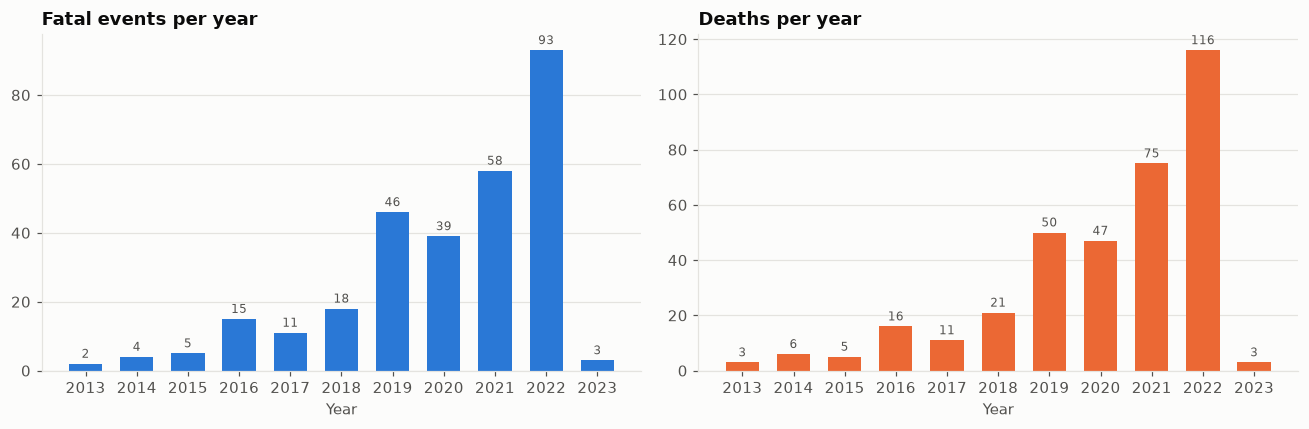

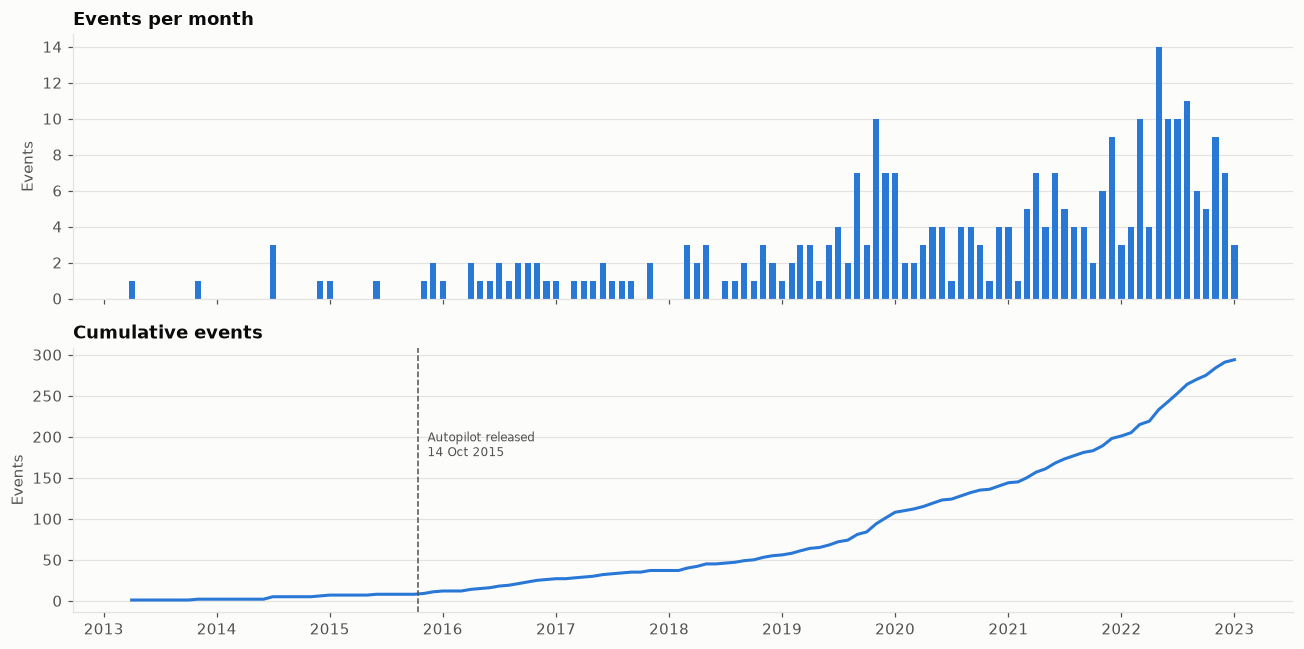

In [11]:
show(P.fig_events_by_year(df)); show(P.fig_monthly_timeline(df))

,events,deaths
date,,
2022-05-28,3,4
2019-11-20,3,3
2022-06-20,3,3
2022-08-14,2,5
2014-07-04,2,4
2020-02-24,2,4
2019-12-29,2,3
2021-04-17,2,3
2021-09-04,2,3


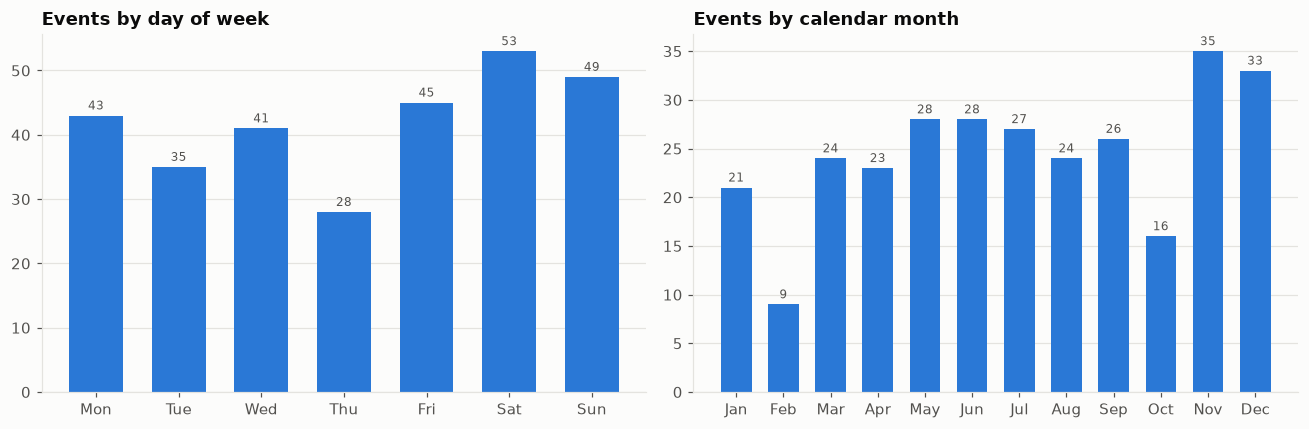

In [12]:
display(A.busiest_dates(df)); show(P.fig_weekday_month(df))

In [13]:
display(A.events_by_country(df).head(10)); display(A.events_by_state(df).head(12))

,events,deaths,share_pct,deaths_per_event
country,,,,
USA,215,261,73.1,1.21
China,16,20,5.4,1.25
Germany,11,16,3.7,1.45
Canada,10,12,3.4,1.20
Netherlands,9,9,3.1,1.00
UK,5,5,1.7,1.00
Norway,4,4,1.4,1.00
Switzerland,3,3,1.0,1.00
Taiwan,3,3,1.0,1.00


,events,deaths,share_pct
state,,,
CA,91,110,42.3
FL,32,40,14.9
GA,9,9,4.2
AZ,8,11,3.7
PA,7,8,3.3
NY,6,7,2.8
OH,6,6,2.8
UT,5,8,2.3
VA,4,7,1.9


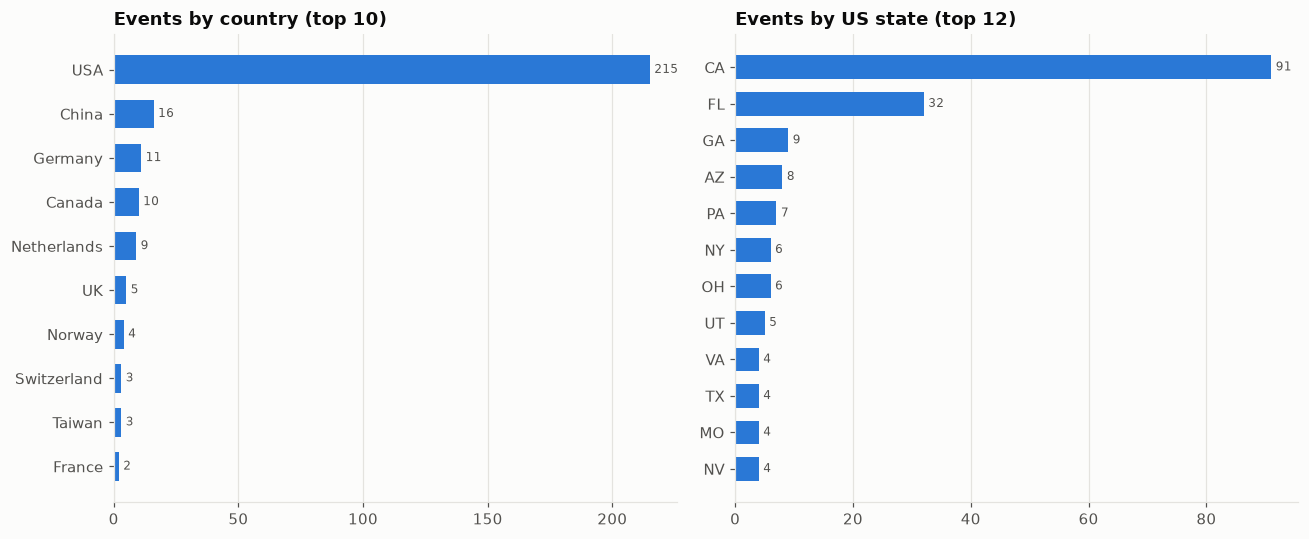

In [14]:
show(P.fig_country_state(df))

**Per year and per day for each country / state**

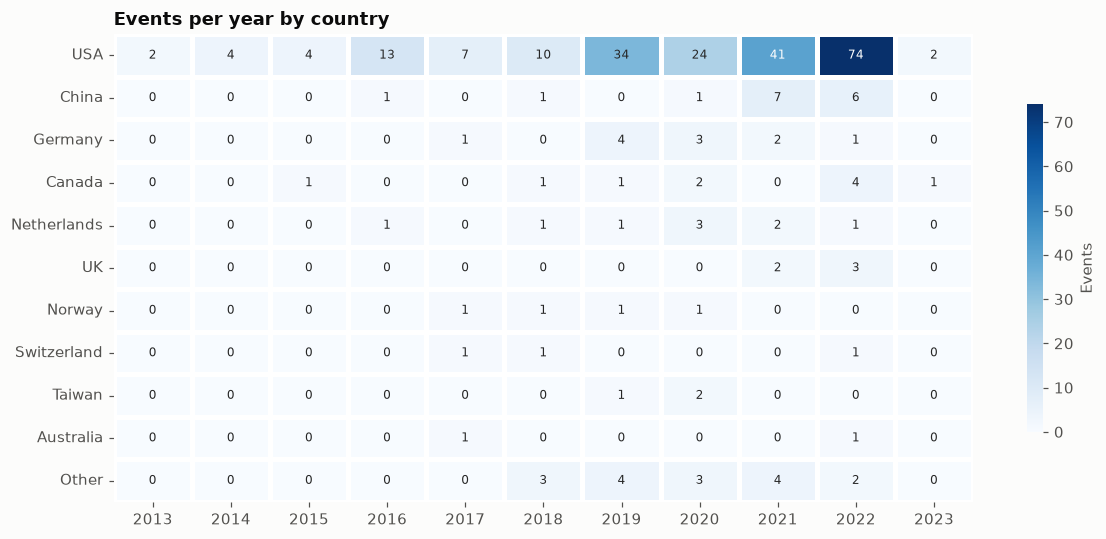

In [15]:
show(P.fig_heatmap(A.country_year_matrix(df), 'Events per year by country'))

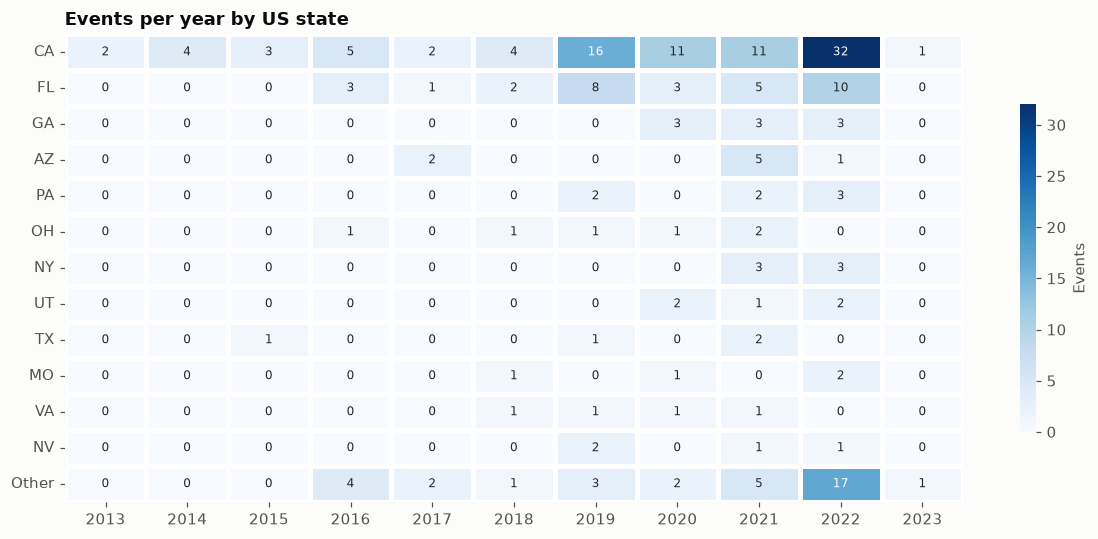

In [16]:
show(P.fig_heatmap(A.state_year_matrix(df), 'Events per year by US state'))

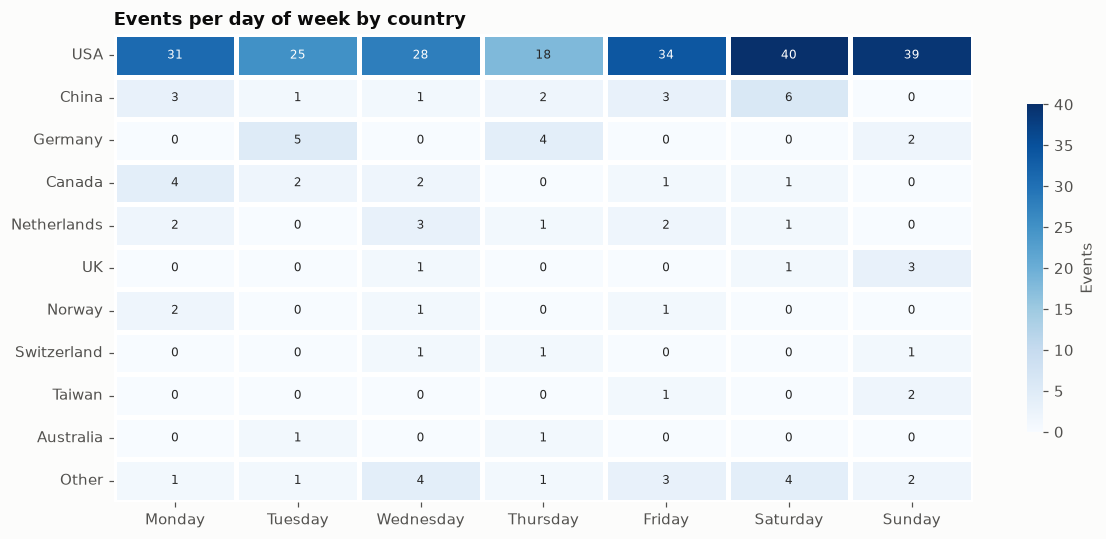

In [17]:
show(P.fig_heatmap(A.country_weekday_matrix(df), 'Events per day of week by country'))

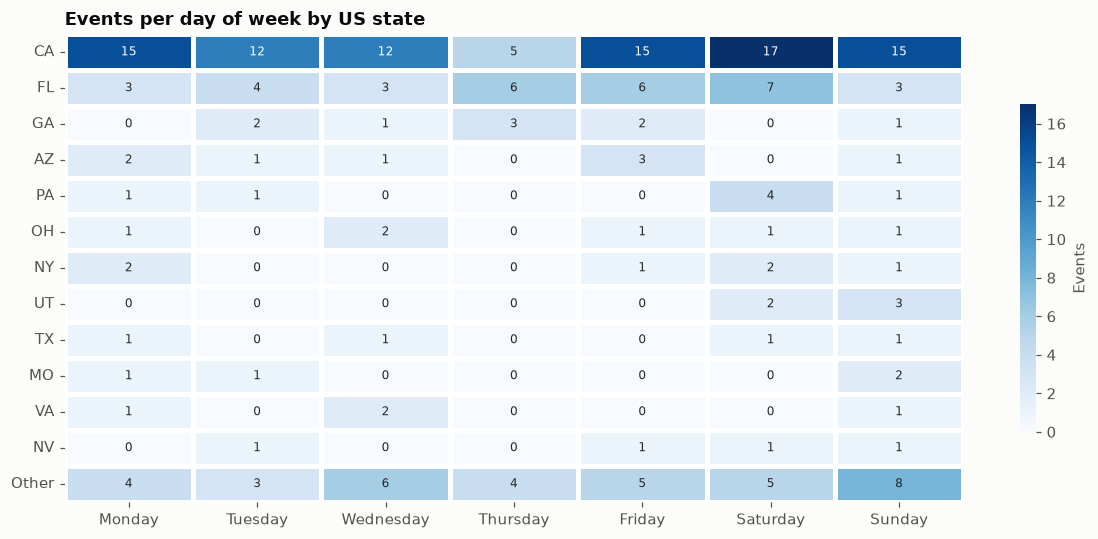

In [18]:
show(P.fig_heatmap(A.state_weekday_matrix(df), 'Events per day of week by US state'))

In [19]:
A.events_per_day_rate(df, 'country').head(10)

,events,first_event,last_event,active_days,events_per_day,events_per_year
country,,,,,,
USA,215,2013-04-02,2023-01-17,3578,0.0601,21.95
China,16,2016-01-20,2022-11-28,2505,0.0064,2.34
Germany,11,2017-01-17,2022-08-16,2038,0.0054,1.97
Canada,10,2015-12-22,2023-01-07,2574,0.0039,1.42
Netherlands,9,2016-09-07,2022-04-08,2040,0.0044,1.61
UK,5,2021-03-13,2022-10-12,579,0.0086,3.14
Norway,4,2017-04-26,2020-05-04,1105,0.0036,1.31
Switzerland,3,2017-11-22,2022-03-13,1573,0.0019,0.69
Taiwan,3,2019-11-24,2020-04-03,132,0.0227,8.29


In [20]:
A.events_per_day_rate(df[df.country == 'USA'], 'state').head(12)

,events,first_event,last_event,active_days,events_per_day,events_per_year
state,,,,,,
CA,91,2013-04-02,2023-01-17,3578,0.0254,9.28
FL,32,2016-05-07,2022-10-18,2356,0.0136,4.97
GA,9,2020-03-08,2022-12-22,1020,0.0088,3.21
AZ,8,2017-07-21,2022-05-23,1768,0.0045,1.64
PA,7,2019-09-07,2022-07-16,1044,0.0067,2.45
OH,6,2016-04-08,2021-11-08,2041,0.0029,1.06
NY,6,2021-06-11,2022-09-12,459,0.0131,4.78
UT,5,2020-01-05,2022-07-24,932,0.0054,1.97
NV,4,2019-09-22,2022-06-03,986,0.0041,1.50


## 2b. Aspects of the death events

**What is the number of victims (deaths) in each accident?**

In [21]:
A.deaths_per_event(df)

,events,share_pct
deaths_in_event,,
1,247,84.0
2,38,12.9
3,6,2.0
4,3,1.0


**How many times did Tesla drivers die?**

In [22]:
A.tesla_driver_deaths(df)

{'events_with_driver_death': 117,
 'driver_deaths': 117,
 'share_of_events_pct': 39.8}

**What is the proportion of events in which one or more occupants died?**

In [23]:
A.occupant_death_proportion(df)

,events,share_pct
Tesla occupant (passenger) died,43,14.6
Tesla driver died,117,39.8
Driver or occupant died,139,47.3
No Tesla driver/occupant died,155,52.7
of which 1 occupant(s) died,39,13.3
of which 2 occupant(s) died,3,1.0
of which 3 occupant(s) died,1,0.3


**What is the distribution of events in which the vehicle hit a cyclist or a pedestrian?**

In [24]:
cp = A.cyclist_ped_distribution(df)
for k, v in cp.items():
    print(k); display(v)

by_count


,events,share_pct
cyclist_ped_deaths,,
0,250,85.0
1,42,14.3
2,2,0.7


by_year


,events
year,
2013,1
2014,0
2015,1
2016,3
2017,2
2018,1
2019,6
2020,5
2021,8


by_country


,events
country,
USA,26
China,8
Australia,2
Germany,2
Canada,2
Taiwan,1
UK,1
France,1
Finland,1


by_model


,events
model,
Unknown,28
Model 3,6
Model S,5
Model X,4
Model Y,1


**How many times did the accident involve the death of a Tesla driver/occupant along with a cyclist or pedestrian?**

In [25]:
A.tesla_and_cyclist_ped(df)

{'events': 1, 'share_of_events_pct': 0.3, 'case_ids': [178]}

**What is the frequency of Tesla colliding with other vehicles?**

In [26]:
ov = A.other_vehicle_frequency(df)
display(ov['by_count']); display(ov['by_year'])

,events,share_pct
other_vehicle_count,,
0,184,62.6
1,95,32.3
2,11,3.7
3,3,1.0
4,1,0.3


,events,with_other_vehicle,share_pct
year,,,
2013,2,1,50.0
2014,4,2,50.0
2015,5,0,0.0
2016,15,6,40.0
2017,11,7,63.6
2018,18,4,22.2
2019,46,23,50.0
2020,39,19,48.7
2021,58,17,29.3


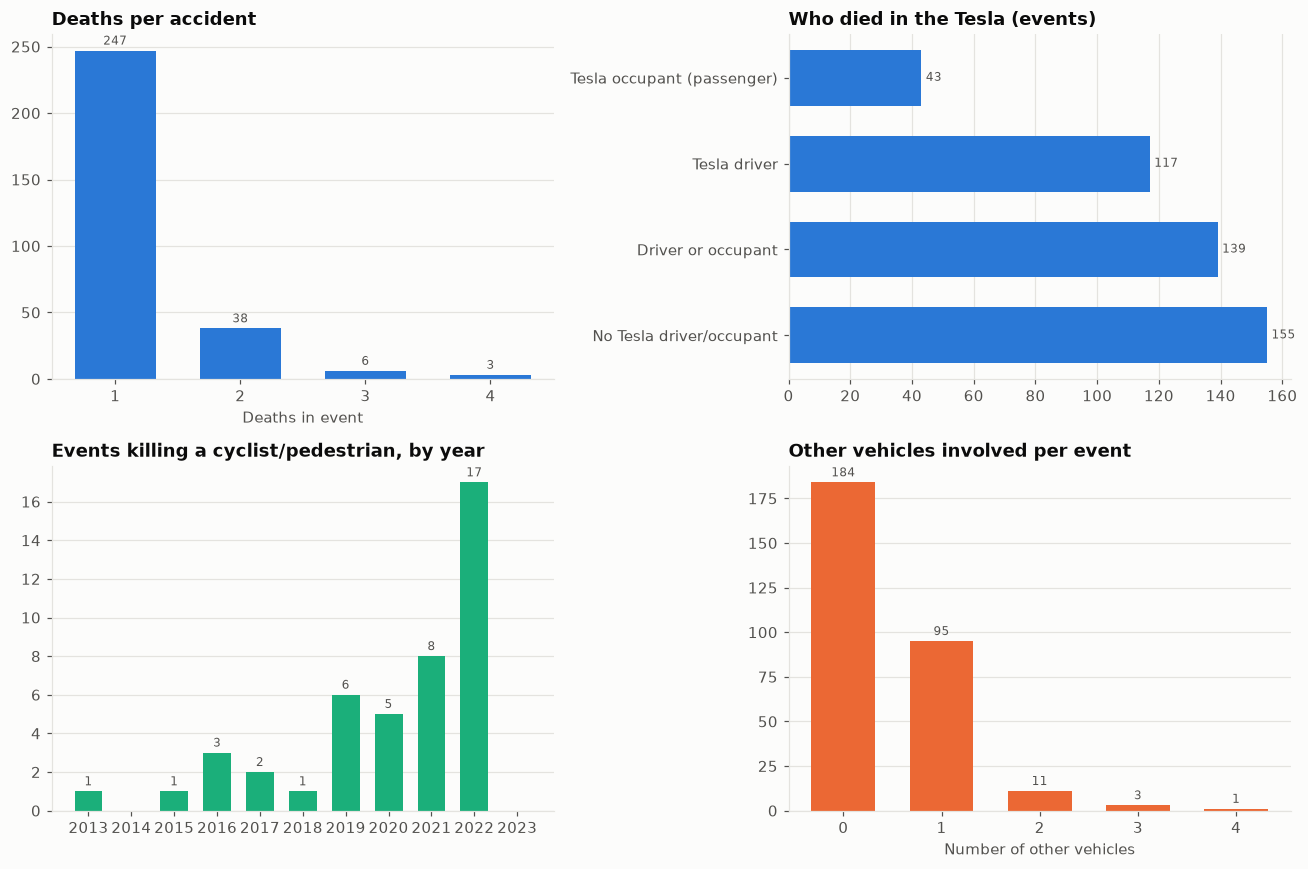

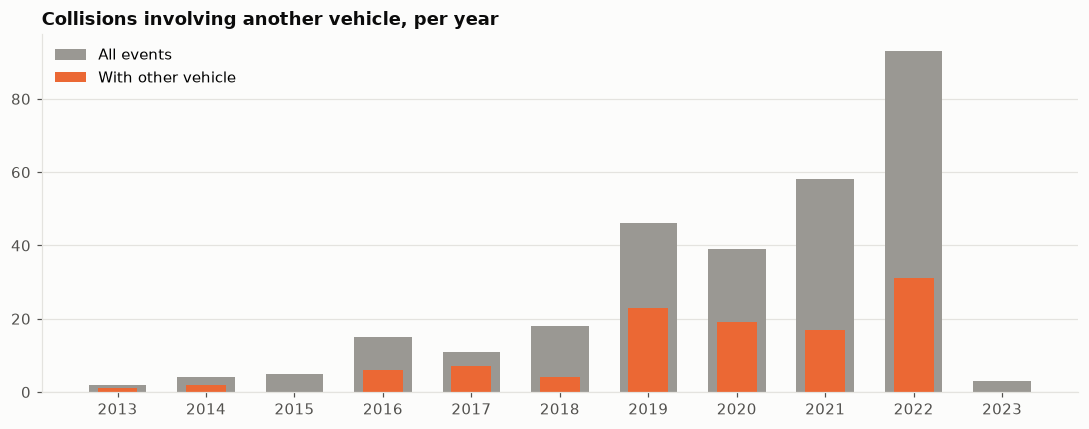

,events,share_pct
victim_group,,
Tesla only,133,45.2
Other vehicle only,104,35.4
Cyclist/ped only,43,14.6
Unattributed,8,2.7
Tesla + other vehicle,5,1.7
Tesla + cyclist/ped,1,0.3


In [27]:
show(P.fig_death_aspects(df)); show(P.fig_other_vehicle_trend(df)); display(A.victim_group_breakdown(df))

## 2c. Event distribution across models

,events,deaths,driver_deaths,cyclist_ped_deaths,autopilot_claimed_events,verified_ap_events,share_pct,share_of_known_pct,deaths_per_event
model,,,,,,,,,
Unknown,183,221,83,28,12,4,62.2,NaN,1.21
Model S,45,53,13,5,7,4,15.3,40.5,1.18
Model 3,39,47,18,6,10,6,13.3,35.1,1.21
Model X,17,19,2,5,4,1,5.8,15.3,1.12
Model Y,10,13,1,2,2,1,3.4,9.0,1.30


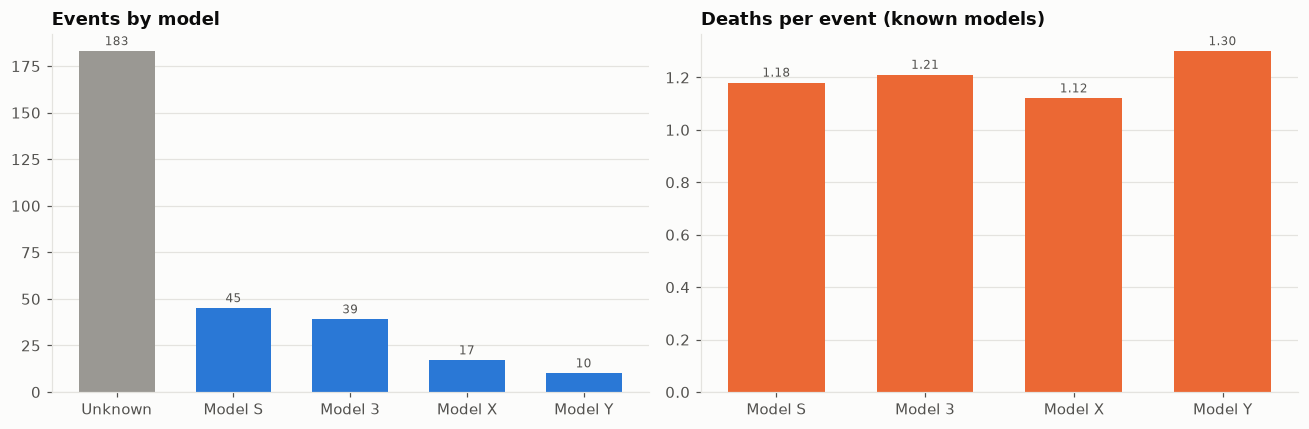

In [28]:
display(A.model_distribution(df)); show(P.fig_models(df))

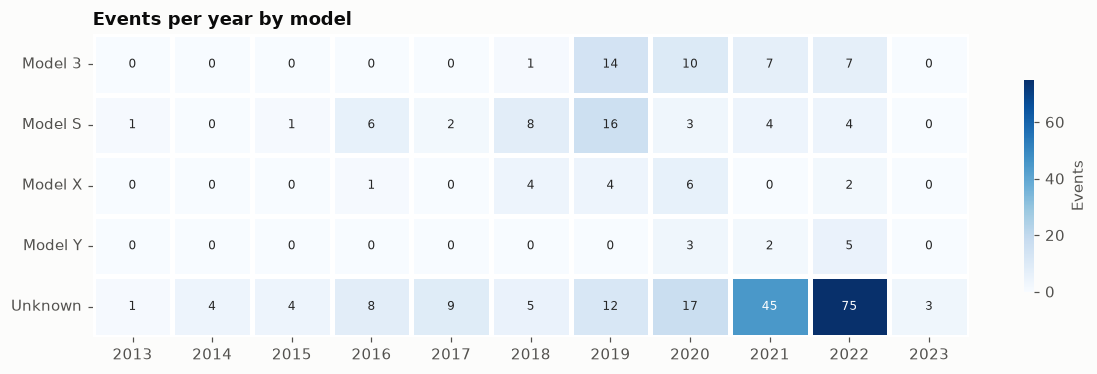

In [29]:
show(P.fig_heatmap(A.model_year_matrix(df), 'Events per year by model', (11, 3.5)))

## 2d. Distribution of verified Tesla autopilot deaths

In [30]:
ap = A.verified_autopilot(df)
ap['summary']

{'verified_events': 16,
 'verified_deaths': 19,
 'verified_plus_nhtsa_deaths': 27,
 'share_of_events_pct': 5.4,
 'share_of_all_deaths_pct': np.float64(5.4),
 'claimed_but_not_verified': 21}

In [31]:
for k in ['by_count', 'funnel', 'by_year', 'by_model', 'by_country', 'by_state']:
    print(k); display(ap[k])

by_count


,events,share_pct
verified_ap_deaths,,
0,278,94.6
1,13,4.4
2,3,1.0


funnel


,events
All events,294
Autopilot claimed,35
Verified AP + NHTSA SGO reported,24
Verified autopilot,16


by_year


,verified_ap_deaths
year,
2013,0
2014,0
2015,0
2016,2
2017,0
2018,2
2019,6
2020,1
2021,1


... (2 outputs left out)

by_country


,verified_ap_deaths
country,
USA,16
China,1
Japan,1
Norway,1


by_state


,verified_ap_deaths
state,
FL,6
CA,5
SC,2
IN,1
NY,1
UT,1


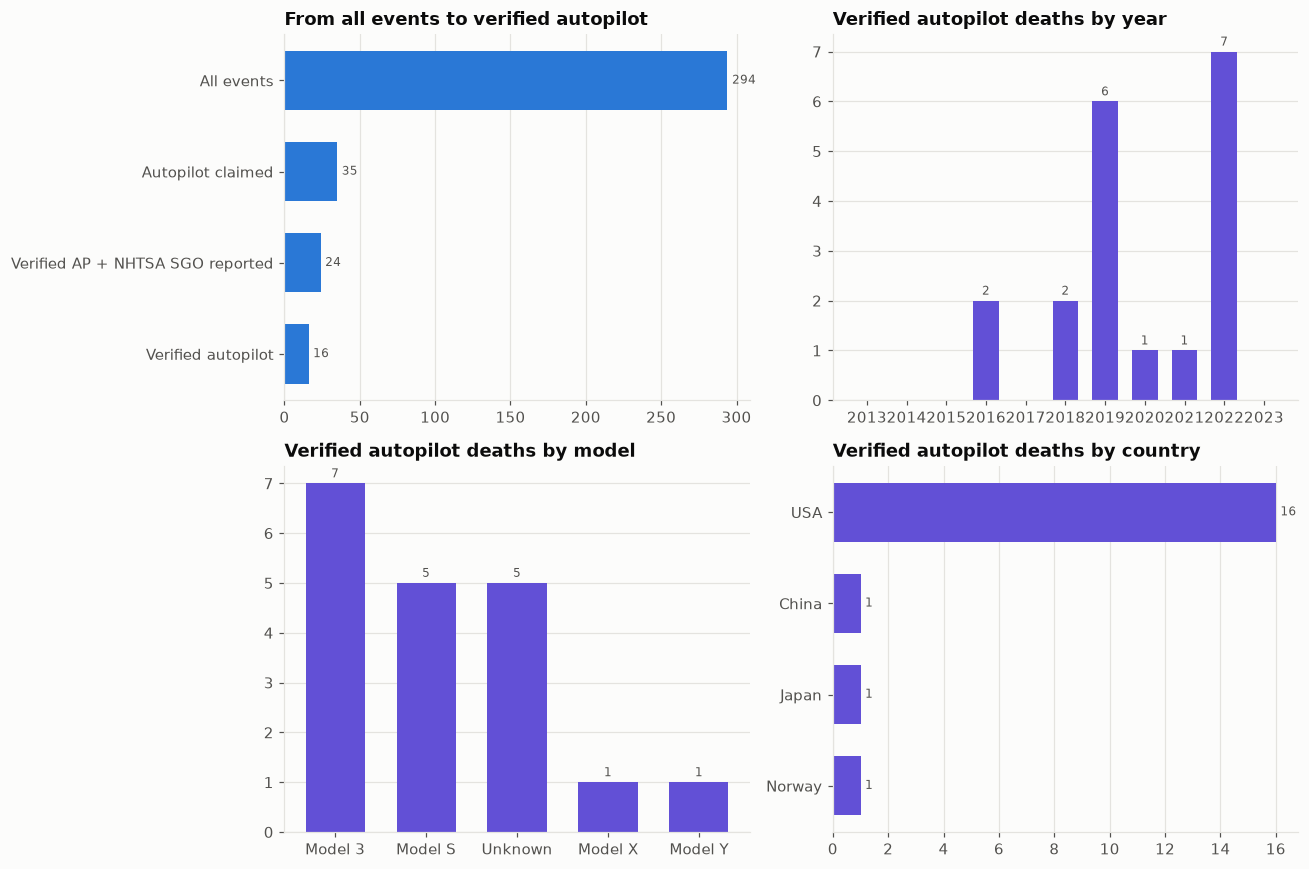

,case_id,date,country,state,model,deaths,verified_ap_deaths,description
11,12,2016-01-20,China,Non-US,Model S,1,1,AutoPilot into street sweeper
14,15,2016-05-07,USA,FL,Unknown,1,1,Autopilot into 18 wheeler
39,40,2018-03-23,USA,CA,Unknown,1,1,Autopilot into highway barrier
41,42,2018-04-29,Japan,Non-US,Model X,1,1,Sleeping Tesla driver kills motorcyclist
58,59,2019-03-01,USA,FL,Model 3,1,1,Autopilot into 18 wheeler
62,63,2019-04-25,USA,FL,Model S,1,1,Tesla kills pedestrian
73,74,2019-08-24,USA,CA,Model 3,1,1,Tesla rear ends Ford
99,100,2019-12-29,USA,CA,Model S,2,2,Tesla runs red light after exiting freeway
100,101,2019-12-29,USA,IN,Model 3,1,1,Tesla rear ends parked fire truck
115,116,2020-05-04,Norway,Non-US,Model S,1,1,Tesla strikes and kills a man standing next to...


In [32]:
show(P.fig_verified_autopilot(df)); ap['cases']

## Export
Runs the full pipeline: cleaned CSV, all tables, figures and `outputs/part2/report.md`.

In [33]:
from autodrive.tesla.pipeline import run
res = run(cfg)
res['report']

20:24:10 | INFO    | part2 | Loaded raw data: 307 rows x 24 columns


20:24:10 | INFO    | part2 | Cleaned data: 294 rows x 29 columns -> C:\Data\09_GIT_Repos\AutonomousDriving\AutonomousDriving\outputs\part2\tesla_deaths_clean.csv


20:24:10 | INFO    | part2 | Wrote 23 tables -> C:\Data\09_GIT_Repos\AutonomousDriving\AutonomousDriving\outputs\part2\tables


20:24:14 | INFO    | part2 | Wrote 14 figures -> C:\Data\09_GIT_Repos\AutonomousDriving\AutonomousDriving\outputs\part2\figures


20:24:14 | INFO    | part2 | Report -> C:\Data\09_GIT_Repos\AutonomousDriving\AutonomousDriving\outputs\part2\report.md


WindowsPath('C:/Data/09_GIT_Repos/AutonomousDriving/AutonomousDriving/outputs/part2/report.md')

## Conclusions
* Fatal events grow every year (2 in 2013 -> 93 in 2022), in line with fleet growth.
* The USA has ~73% of events; California alone ~42% of US events.
* Most events kill one person; the Tesla driver died in ~40% of events.
* Cyclists/pedestrians died in ~15% of events; another vehicle was involved in ~37%.
* Model is unknown for most cases; among known models Model S and Model 3 dominate.
* **Verified autopilot deaths are a small share** (19 deaths in 16 events, ~5% of events); autopilot was *claimed* in more events than could be verified.
* **Limitation:** without miles driven with and without autopilot, this data cannot show whether autopilot makes driving safer or riskier per mile - only how many fatal events were linked to it.